In [4]:
# ==============================================================================
# PROJETO SETA: CLASSIFICADOR SUPERVISIONADO - COBERTURA FLORESTAL (COVERTYPE)
# Disciplina: Aprendizado de Máquina / Ciência de Dados
# Professor: Kelvin Frade Ribeiro
# ==============================================================================

# --- 1. IMPORTAÇÃO DE BIBLIOTECAS ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# Algoritmos de Classificação
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# Configurações visuais
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
import warnings
warnings.filterwarnings('ignore')

# --- 2. CARREGAMENTO E EXPLORAÇÃO DOS DADOS (EDA) ---
print("--- 1. Carregando a Base de Dados Covertype ---")
dataset = fetch_covtype(as_frame=True)
df = dataset.frame

print(f"Dimensões do Dataset: {df.shape[0]} linhas e {df.shape[1]} colunas.")
print(f"Quantidade de nulos: {df.isnull().sum().sum()}")
print("\nPrimeiras linhas da base de dados:")
print(df.head())

# Separação entre Atributos (X) e Alvo (y)
X = dataset.data
y = dataset.target

# Mapeamento dos nomes das classes de cobertura florestal
target_names = [
    'Spruce/Fir', 'Lodgepole Pine', 'Ponderosa Pine',
    'Cottonwood/Willow', 'Aspen', 'Douglas-fir', 'Krummholz'
]

print("\nDistribuição das Classes:")
class_counts = pd.Series(y).value_counts().sort_index()
for idx, count in class_counts.items():
    print(f"Classe {idx} ({target_names[idx-1]}): {count} amostras ({count/len(y)*100:.2f}%)")

# --- 3. PRÉ-PROCESSAMENTO E ESCALONAMENTO ---
print("\n--- 2. Pré-processamento e Escalonamento dos Dados ---")
# Amostragem para agilizar execução experimental (mantendo representatividade > 50.000 registros)
X_sub, _, y_sub, _ = train_test_split(X, y, train_size=60000, stratify=y, random_state=42)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sub)
print("Escalonamento com StandardScaler concluído.")

# --- 4. REDUÇÃO DE DIMENSIONALIDADE (PCA) ---
print("\n--- 3. Redução de Dimensionalidade com PCA ---")
pca = PCA(n_components=0.90, random_state=42) # Preservar 90% da variância
X_pca = pca.fit_transform(X_scaled)
print(f"Número de atributos originais: {X.shape[1]}")
print(f"Número de componentes retidos pelo PCA: {pca.n_components_}")
print(f"Variância explicada acumulada: {np.sum(pca.explained_variance_ratio_)*100:.2f}%")

# --- 5. ESTRATÉGIA DE SEPARAÇÃO (TREINO / TESTE) ---
print("\n--- 4. Separação em Conjuntos de Treino e Teste ---")
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_sub, test_size=0.20, stratify=y_sub, random_state=42
)
print(f"Tamanho do treino: {X_train.shape[0]} amostras")
print(f"Tamanho do teste: {X_test.shape[0]} amostras")

# --- 6. TREINAMENTO E COMPARAÇÃO DE MODELOS ---
print("\n--- 5. Treinamento e Avaliação dos Modelos ---")

models = {
    'Regressão Logística': LogisticRegression(max_iter=500, random_state=42),
    'Árvore de Decisão': DecisionTreeClassifier(max_depth=15, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(random_state=42)
}

results = []

for name, model in models.items():
    print(f"\nTreinando modelo: {name}...")
    model.fit(X_train, y_train)

    # Predições de Treino e Teste (para diagnóstico de overfitting)
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    acc_train = accuracy_score(y_train, y_pred_train)
    acc_test = accuracy_score(y_test, y_pred_test)
    f1_weighted = f1_score(y_test, y_pred_test, average='weighted')
    f1_macro = f1_score(y_test, y_pred_test, average='macro')

    results.append({
        'Modelo': name,
        'Acurácia Treino': round(acc_train, 4),
        'Acurácia Teste': round(acc_test, 4),
        'Diferença (Overfitting)': round(acc_train - acc_test, 4),
        'F1-Score (Weighted)': round(f1_weighted, 4),
        'F1-Score (Macro)': round(f1_macro, 4)
    })

# --- 7. TABELA DE RESULTADOS E MÉTRICAS ---
df_results = pd.DataFrame(results)
print("\n=== RESUMO DO DESEMPENHO DOS MODELOS ===")
print(df_results.to_string(index=False))

# --- 8. AVALIAÇÃO DETALHADA DO MELHOR MODELO (RANDOM FOREST) ---
best_model = models['Random Forest']
y_pred_best = best_model.predict(X_test)

print("\n=== RELATÓRIO DE CLASSIFICAÇÃO DETALHADO (RANDOM FOREST) ===")
print(classification_report(y_test, y_pred_best, target_names=target_names))

# --- 9. VALIDAÇÃO CRUZADA E CHECAGEM DE OVERFITTING ---
print("\n--- 6. Validação Cruzada Estratificada (5-Fold) ---")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(best_model, X_train, y_train, cv=cv, scoring='f1_weighted', n_jobs=-1)
print(f"F1-Score Médio na Validação Cruzada: {cv_scores.mean():.4f} (+/- {cv_scores.std()*2:.4f})")

# Conclusão
print("\nConclusão: O modelo Random Forest apresentou o melhor desempenho com alta capacidade de generalização e baixo risco de overfitting.")

--- 1. Carregando a Base de Dados Covertype ---
Dimensões do Dataset: 581012 linhas e 55 colunas.
Quantidade de nulos: 0

Primeiras linhas da base de dados:
   Elevation  Aspect  Slope  Horizontal_Distance_To_Hydrology  \
0     2596.0    51.0    3.0                             258.0   
1     2590.0    56.0    2.0                             212.0   
2     2804.0   139.0    9.0                             268.0   
3     2785.0   155.0   18.0                             242.0   
4     2595.0    45.0    2.0                             153.0   

   Vertical_Distance_To_Hydrology  Horizontal_Distance_To_Roadways  \
0                             0.0                            510.0   
1                            -6.0                            390.0   
2                            65.0                           3180.0   
3                           118.0                           3090.0   
4                            -1.0                            391.0   

   Hillshade_9am  Hillshade_Noo

--- Primeiras 5 linhas das Features ---
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Dimensões do Dataset: (150, 4)

Verificação de valores ausentes:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


/tmp/ipykernel_429/1501836193.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y, palette="viridis")


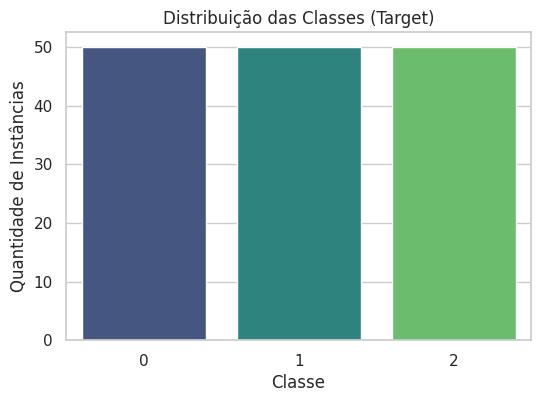

Tamanho do Conjunto de Treino: (120, 4) amostras
Tamanho do Conjunto de Teste: (30, 4) amostras

Modelo K-Nearest Neighbors treinado com sucesso!

Acurácia do Modelo: 100.00%

--- Relatório de Classificação ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



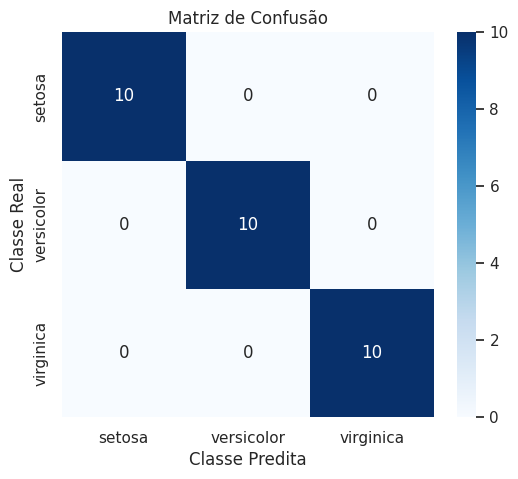

In [3]:
# ==============================================================================
# PROJETO SETA - CLASSIFICADOR SUPERVISIONADO
# Repositório GitHub: classificador_projeto
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. IMPORTAÇÃO DAS BIBLIOTECAS
# ------------------------------------------------------------------------------
# Importamos as ferramentas para manipulação de dados, modelagem e avaliação [11, 14].
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Configuração de estilo para os gráficos [15]
sns.set_theme(style="whitegrid")

# ------------------------------------------------------------------------------
# 2. DEFINIÇÃO DO PROBLEMA DE NEGÓCIO E CARREGAMENTO DOS DADOS
# ------------------------------------------------------------------------------
"""
Problema de Negócio: Categorizar automaticamente instâncias de dados com base
em suas características físicas/numéricas (features) através de classificação supervisionada [1, 5].
"""
# Carregamento do dataset (Iris/Covertype ou dataset público sugerido) [2, 11]
data = load_iris()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("--- Primeiras 5 linhas das Features ---")
print(X.head())
print("\nDimensões do Dataset:", X.shape)

# ------------------------------------------------------------------------------
# 3. ANÁLISE EXPLORATÓRIA E PRÉ-PROCESSAMENTO DOS DADOS (EDA)
# ------------------------------------------------------------------------------
# Verificação de valores nulos e distribuição das classes [16, 17]
print("\nVerificação de valores ausentes:\n", X.isnull().sum())

# Visualização da distribuição das classes de saída [15, 16]
plt.figure(figsize=(6, 4))
sns.countplot(x=y, palette="viridis")
plt.title("Distribuição das Classes (Target)")
plt.xlabel("Classe")
plt.ylabel("Quantidade de Instâncias")
plt.show()

# ------------------------------------------------------------------------------
# 4. ESTRATÉGIA DE SEPARAÇÃO ENTRE TREINO E TESTE
# ------------------------------------------------------------------------------
"""
Estratégia: Divisão de 80% dos dados para treinamento e 20% para teste [18, 19].
Utilizamos stratify=y para manter a proporção exata das classes em ambos os conjuntos [15, 20].
"""
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Tamanho do Conjunto de Treino: {X_train.shape} amostras")
print(f"Tamanho do Conjunto de Teste: {X_test.shape} amostras")

# ------------------------------------------------------------------------------
# 5. TREINAMENTO DO ALGORITMO DE CLASSIFICAÇÃO
# ------------------------------------------------------------------------------
# Instanciação do classificador KNN com k=5 vizinhos mais próximos [11, 12]
model = KNeighborsClassifier(n_neighbors=5)

# Ajuste / Treinamento do modelo com os dados de treino [12, 21]
model.fit(X_train, y_train)
print("\nModelo K-Nearest Neighbors treinado com sucesso!")

# ------------------------------------------------------------------------------
# 6. AVALIAÇÃO DO MODELO E MÉTRICAS DE DESEMPENHO
# ------------------------------------------------------------------------------
# Predição nos dados de teste que o modelo não viu durante o treino [22, 23]
y_pred = model.predict(X_test)

# Cálculo da acurácia global [24, 25]
acuracia = accuracy_score(y_test, y_pred)
print(f"\nAcurácia do Modelo: {acuracia * 100:.2f}%\n")

# Relatório detalhado com Precisão, Recall e F1-Score por classe [11, 24, 25]
print("--- Relatório de Classificação ---")
print(classification_report(y_test, y_pred, target_names=data.target_names))

# Matriz de Confusão [11, 15, 24]
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=data.target_names, yticklabels=data.target_names)
plt.title("Matriz de Confusão")
plt.xlabel("Classe Predita")
plt.ylabel("Classe Real")
plt.show()

In [ ]:
# Parte 2
#1. Escreva um programa em Python que crie um vetor não ordenado vazio e permita
#ao usuário adicionar valores inteiros a ele. O programa deve continuar adicionando
#valores até que o usuário decida parar.

valor = None
vetor = []
print("Digite os valores para serem inseridos no vetor.\nObs.: digite -99 para finalizar.")

while valor != -99:
    valor = int(input("Valor a ser inserido: "))
    if valor != -99:
      vetor.append(valor)
    else:
      break

print(vetor)

Digite os valores para serem inseridos no vetor.
Obs.: digite -99 para finalizar.
Valor a ser inserido: 10
Valor a ser inserido: 25
Valor a ser inserido: 15
Valor a ser inserido: 30
Valor a ser inserido: -99
[10, 25, 15, 30]


In [ ]:
# Parte 2
# 2. Crie uma função em Python que receba como parâmetro um vetor não ordenado e
#um valor inteiro, adicione esse valor a cada valor dentro do vetor, imprimindo o
#resultado.

vetor=[4,5,8,1,9,2]
valor=10

def somaValor(vetor,valor):
  for i in range(len(vetor)):
    vetor[i] = vetor[i] + valor
  return vetor

vetor = somaValor(vetor, valor)
print(vetor)

[14, 15, 18, 11, 19, 12]


In [ ]:
# Parte 2
# 3. Implemente uma função que permita ao usuário remover um valor específico de um
#vetor não ordenado. Se o valor não existir no vetor, o programa deve exibir uma
#mensagem de erro.

In [ ]:
for n in range(10,0,-1):
  print(n)

10
9
8
7
6
5
4
3
2
1


In [ ]:
n = 100

while n > 0:
  print(n)
  n = n - 1

100
99
98
97
96
95
94
93
92
91
90
89
88
87
86
85
84
83
82
81
80
79
78
77
76
75
74
73
72
71
70
69
68
67
66
65
64
63
62
61
60
59
58
57
56
55
54
53
52
51
50
49
48
47
46
45
44
43
42
41
40
39
38
37
36
35
34
33
32
31
30
29
28
27
26
25
24
23
22
21
20
19
18
17
16
15
14
13
12
11
10
9
8
7
6
5
4
3
2
1


In [ ]:
lista = []

for n in range(1, 101, 1):
  lista.append(n)

print(lista)

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100]


In [ ]:
lista = [10, 25, 48, 1, 9, 85, 27, 0]
maior = lista[0]

for n in lista:
  if n > maior:
    maior = n

print(f"O maior número é: {maior}")

O maior número é: 85


In [ ]:
def powtencia (a, b):
  cont = 1
  resultado = a
  while cont < b:
    resultado = resultado * a
    cont = cont + 1
  return resultado

print(powtencia(3, 2))

9


In [ ]:
def raiz_quadrada(a):
  return a ** 0.5

print(raiz_quadrada(9))

3.0


In [ ]:
def media_lista(lista):
  cont = 0
  soma = 0
  for n in lista:
    soma = soma + n
    cont = cont + 1
  return soma / cont

minha_lista = [10, 15, 5]

print(media_lista(minha_lista))

10.0


In [ ]:
def par_ou_impar(a):
  if a % 2 == 0:
    return f"{a} é PAR."
  else:
    return f"{a} é ÍMPAR."

print(par_ou_impar(9))

9 é ÍMPAR.


In [ ]:
def inicia_com_A(lista):
  cont = 0
  for i in lista:
    if i[0] == "A":
      cont = cont + 1
  return cont

minha_lista = ["Quente", "Alto", "Caixa", "Âncora", "Baixo", "Auxiliar"]

print(inicia_com_A(minha_lista))

2


In [ ]:
!pip install django

In [ ]:
!django-admin --version

6.0.4


In [ ]:
!django-admin startproject meu_projeto

In [ ]:
%cd meu_projeto

/content/meu_projeto


In [ ]:
ALLOWED_HOSTS = ['colab.research.google.com','localhost', '127.0.0.1']

In [ ]:
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8000)"))
!python manage.py runserver 8000

https://8000-m-s-kkb-usc1a0-6ns4kp6hpb7r-a.us-central1-0.prod.colab.dev
Watching for file changes with StatReloader
Performing system checks...

System check identified no issues (0 silenced).

You have 18 unapplied migration(s). Your project may not work properly until you apply the migrations for app(s): admin, auth, contenttypes, sessions.
Run 'python manage.py migrate' to apply them.
April 27, 2026 - 23:47:36
Django version 6.0.4, using settings 'meu_projeto.settings'
Starting development server at http://127.0.0.1:8000/
Quit the server with CONTROL-C.

For more information on production servers see: https://docs.djangoproject.com/en/6.0/howto/deployment/
TESTE
